# Exploratory Data Analysis: Health Insurance Claims

Step 3 of the project (see `docs/methodology.md`).

This notebook explores 1,332 policyholders (the cleaned table from Step 2) to understand how claim amounts vary and which characteristics go along with higher claims. The sections follow the order in which the exploration happened. Each one asks a question, shows a chart, and records what was seen at that point, including open questions that later sections pick up. Nothing here is a final conclusion: the patterns become hypotheses that Step 4 tests with formal statistics.

Things to keep in mind while reading:

- The units of `claim` are undocumented, so amounts are shown as plain numbers.
- The origin of the data is undocumented, and several patterns below suggest it may be synthetic. Findings describe this dataset only, not real-world insurance.
- Everything here is association, not cause. Smokers having higher claims does not by itself show that smoking causes them.
- Medians are used as the typical value because claims are skewed: a minority of very large claims pulls the average up.
- The numbers in each table come from SQL queries in `sql/`, named at the end of each section.

## Summary of findings

Written after the exploration was finished, and placed here for readers who want the results first.

1. Claims are right-skewed. Half of all claims fall between about 4,800 and 16,800, but a minority exceed 60,000.
2. Smoking is the largest single difference. Smokers' median claim is about 4 to 5 times that of non-smokers.
3. Among smokers, BMI splits claims into two groups. Smokers with a BMI of 30 or more (the medical threshold for obesity) have a median claim about twice that of smokers below 30. For non-smokers, BMI makes little difference. This is an interaction between smoking and BMI.
4. Higher blood pressure goes with higher claims, but among smokers it mostly overlaps with BMI.
5. The northeast has higher claims than the other regions, even among non-smokers.
6. Age, gender, diabetic status and number of children show little relationship with claims.
7. A data quirk: men in the data are aged 18 to 50 and women 25 to 60, so gender and age are tangled together.

## Contents

1. How are claim amounts distributed?
2. Smoking: the largest difference
3. Why do smokers split into two groups?
4. Smoking and BMI together
5. Blood pressure
6. The remaining variables: gender, region, diabetic status and children
7. A data quirk: men and women cover different age ranges
8. Correlation matrix
9. What to test in Step 4

## Setup

Load the cleaned table from the DuckDB database built by `sql/01_load/`. A readable smoking label is added for chart legends, and each group gets a fixed color so it looks the same in every chart.

In [1]:
import os
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Run from the project root so relative paths work the same everywhere
if Path.cwd().name == "notebooks":
    os.chdir("..")

# Load the cleaned table, then close the connection
# so the DuckDB shell isn't locked out
con = duckdb.connect("data/processed/insurance.duckdb", read_only=True)
df = con.sql("SELECT * FROM insurance_cleaned").df()
con.close()

# Readable label for chart legends
df["smoking"] = df["smoker"].map({True: "Smoker", False: "Non-smoker"})

# Fixed colors so each group looks the same in every chart
SMOKING_COLORS = {"Non-smoker": "#2a78d6", "Smoker": "#eb6834"}
GENDER_COLORS = {"female": "#1baf7a", "male": "#4a3aa7"}
BASE_COLOR = "#2a78d6"

sns.set_theme(style="whitegrid")

print(df.shape)
df.head()

(1332, 11)


,Id,age,gender,bmi,bloodpressure,diabetic,children,smoker,region,claim,smoking
0,1,39.0,male,23.2,91,True,0,False,southeast,1121.87,Non-smoker
1,2,24.0,male,30.1,87,False,0,False,southeast,1131.51,Non-smoker
2,8,19.0,male,41.1,100,False,0,False,northwest,1146.80,Non-smoker
3,9,20.0,male,43.0,86,False,0,False,northwest,1149.40,Non-smoker
4,10,30.0,male,53.1,97,False,0,False,northwest,1163.46,Non-smoker


## 1. How are claim amounts distributed?

Before comparing groups, it helps to know what a typical claim looks like and whether a few extreme values dominate. The left chart shows raw amounts. The right chart shows the logarithm of each claim, a common transformation for skewed money values that compresses the large ones.

count     1332.0
mean     13325.0
std      12110.0
min       1122.0
25%       4760.0
50%       9413.0
75%      16781.0
max      63770.0
Name: claim, dtype: float64
Skewness, raw claims: 1.51
Skewness, log(claim): -0.07
Share of claims over 30,000: 12.2%


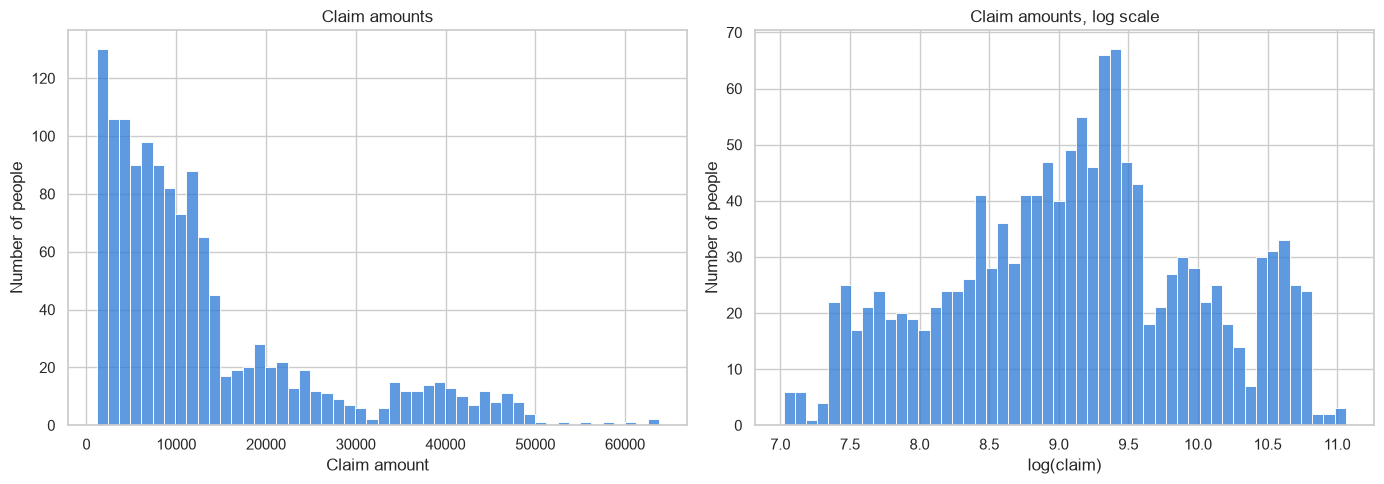

In [2]:
print(df["claim"].describe().round(0))
print(f"Skewness, raw claims: {df['claim'].skew():.2f}")
print(f"Skewness, log(claim): {np.log(df['claim']).skew():.2f}")
print(f"Share of claims over 30,000: {(df['claim'] > 30000).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x="claim", bins=50, color=BASE_COLOR, ax=axes[0])
axes[0].set_title("Claim amounts")
axes[0].set_xlabel("Claim amount")
axes[0].set_ylabel("Number of people")

sns.histplot(x=np.log(df["claim"]), bins=50, color=BASE_COLOR, ax=axes[1])
axes[1].set_title("Claim amounts, log scale")
axes[1].set_xlabel("log(claim)")
axes[1].set_ylabel("Number of people")

plt.tight_layout()
plt.show()

What this shows:

- Claims are right-skewed (skewness 1.51): most are small, with a long tail of large claims.
- The median is 9,413 and the mean 13,325. The large claims pull the mean about 3,900 above the median, which is why medians are used as the typical value from here on.
- The middle half of claims falls between 4,760 and 16,781, and about 12% exceed 30,000.
- There is a small second bump around 35,000 to 40,000. It is not clear yet what causes it. One possibility is a subgroup of people with much higher claims.
- On the log scale the long right tail disappears and the skewness is close to zero (-0.07). The shape is still lumpy, with several peaks, which could mean the data mixes groups with very different claim levels. A skewness near zero does not mean the distribution is normal, so Step 4 compares models on raw and log claims by checking their residuals rather than assuming one is better.

## 2. Smoking: the largest difference

Smoking is the most obvious candidate for higher claims, so it comes first. The box plot compares typical values and spread; the histogram shows the full shape of each group.

How to read a box plot: the line inside the box is the median, the box covers the middle 50% of values, and dots are unusually high or low values (more than 1.5 box-heights beyond the box).

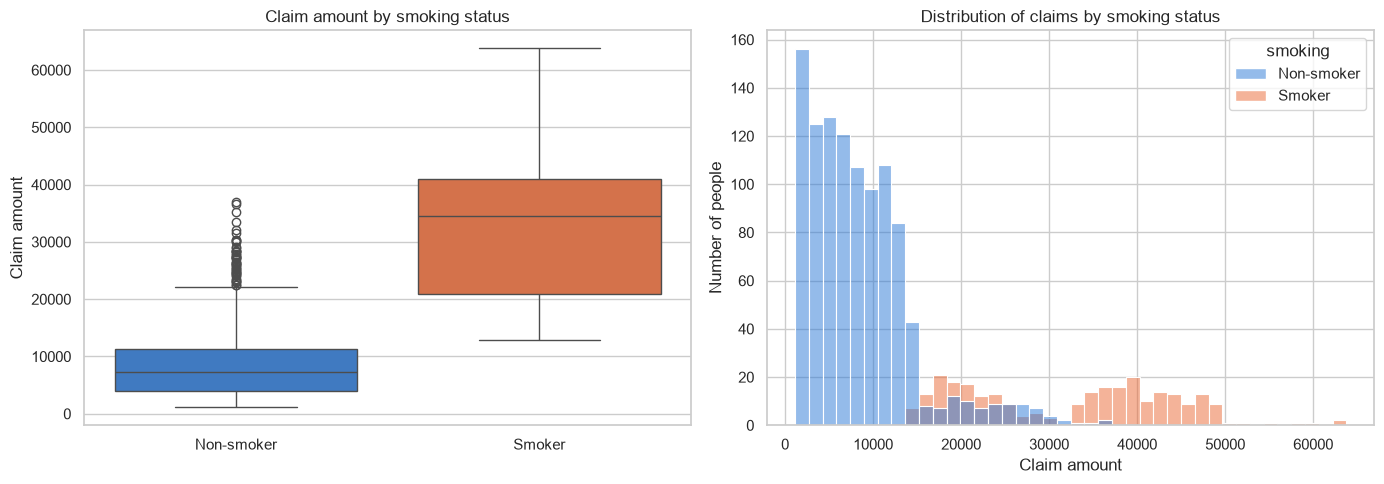

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x="smoking", y="claim", hue="smoking",
            palette=SMOKING_COLORS, legend=False, ax=axes[0])
axes[0].set_title("Claim amount by smoking status")
axes[0].set_xlabel("")
axes[0].set_ylabel("Claim amount")

sns.histplot(data=df, x="claim", hue="smoking", palette=SMOKING_COLORS,
             bins=40, ax=axes[1])
axes[1].set_title("Distribution of claims by smoking status")
axes[1].set_xlabel("Claim amount")
axes[1].set_ylabel("Number of people")

plt.tight_layout()
plt.show()

What this shows:

| | n | Median claim | Middle 50% of claims | Unusual values |
|---|---|---|---|---|
| Non-smokers | 1,058 | 7,365 | 4,034 to 11,365 | 47 |
| Smokers | 274 | 34,456 | 20,826 to 41,019 | 0 |

- Smokers' median claim is about 4 to 5 times that of non-smokers.
- Smokers' claims also vary much more: their middle 50% spans about 20,200, compared with 7,300 for non-smokers.
- Some non-smokers have unusually high claims, up to about 37,000, well inside the smokers' range. This suggests that other factors besides smoking are linked to high claims.
- The two groups have different shapes. Non-smokers bunch at the low end with a right tail. Smokers have two peaks, around 20,000 and 40,000, which suggests two subgroups mixed together.

Open question: what separates the two groups of smokers?

Query: `sql/03_analysis/01_claim_by_smoker.sql`

## 3. Why do smokers split into two groups?

If smokers form two groups, another variable may separate them. This section looks at smokers only and checks three candidates: gender, age and BMI. If a variable explains the split, the two peaks should line up with different values of it.

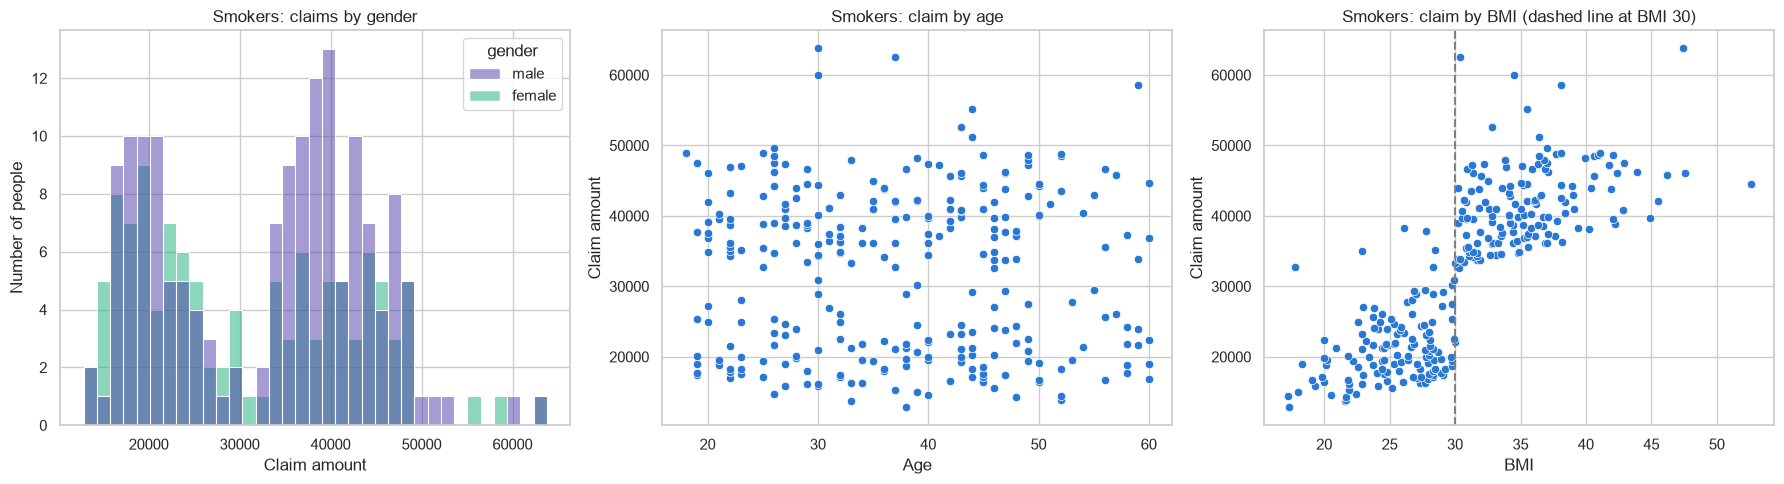

In [4]:
smokers = df[df["smoker"]]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(data=smokers, x="claim", hue="gender", palette=GENDER_COLORS,
             bins=35, ax=axes[0])
axes[0].set_title("Smokers: claims by gender")
axes[0].set_xlabel("Claim amount")
axes[0].set_ylabel("Number of people")

sns.scatterplot(data=smokers, x="age", y="claim", color=BASE_COLOR, ax=axes[1])
axes[1].set_title("Smokers: claim by age")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Claim amount")

sns.scatterplot(data=smokers, x="bmi", y="claim", color=BASE_COLOR, ax=axes[2])
axes[2].axvline(30, color="gray", linestyle="--")
axes[2].set_title("Smokers: claim by BMI (dashed line at BMI 30)")
axes[2].set_xlabel("BMI")
axes[2].set_ylabel("Claim amount")

plt.tight_layout()
plt.show()

What this shows:

- Gender does not explain the split: men and women appear in both peaks.
- Age does not either: both bands of claims, around 20,000 and around 40,000, stretch across the full age range.
- BMI does. Claims jump sharply at a BMI of 30, the standard medical threshold for obesity.

| Smokers | n | Median claim | Claims over 30,000 |
|---|---|---|---|
| BMI under 30 | 129 | 20,167 | 8 of 129 |
| BMI 30 or more | 145 | 40,904 | 144 of 145 |

This likely accounts for the second bump seen in section 1, since smokers with a BMI of 30 or more cluster around 35,000 to 50,000. A cutoff this clean is unusual in real data and is one of several signs that the dataset may be synthetic.

Open question: is this jump specific to smokers, or does BMI matter the same way for everyone?

Query: `sql/03_analysis/02_smoker_bmi_segments.sql`

## 4. Smoking and BMI together

Does the jump at BMI 30 also happen for non-smokers? This chart shows everyone, colored by smoking status, with a dashed line at BMI 30.

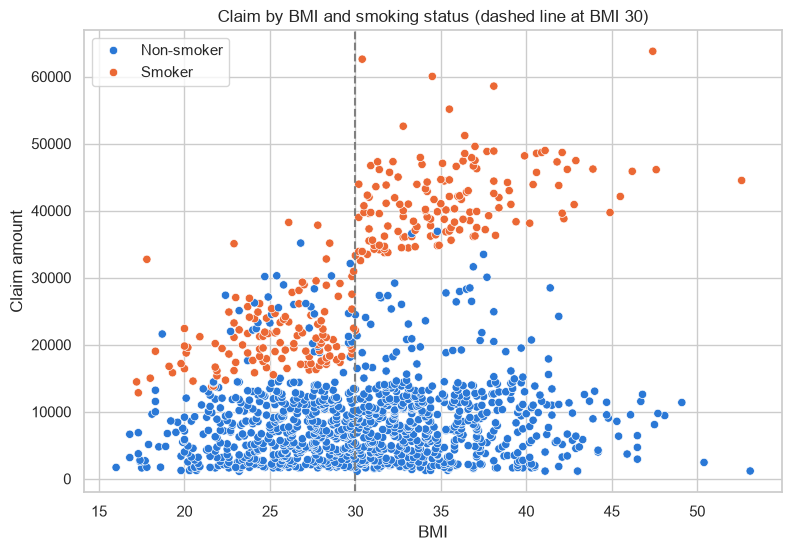

In [5]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="bmi", y="claim", hue="smoking", palette=SMOKING_COLORS)
plt.axvline(30, color="gray", linestyle="--")
plt.title("Claim by BMI and smoking status (dashed line at BMI 30)")
plt.xlabel("BMI")
plt.ylabel("Claim amount")
plt.legend(title="")
plt.show()

What this shows:

| Median claim | BMI under 30 | BMI 30 or more | Change at BMI 30 |
|---|---|---|---|
| Non-smokers | 6,770 (n=501) | 8,117 (n=557) | +1,347 |
| Smokers | 20,167 (n=129) | 40,904 (n=145) | +20,737 |

- Among non-smokers, a BMI of 30 or more goes with only a small increase, about 1,300.
- Among people with a BMI under 30, smokers' median claim is about 13,400 higher than non-smokers'.
- Among smokers, a BMI of 30 or more goes with an increase of about 20,700, roughly 15 times the increase for non-smokers.

This looks like an interaction: the relationship between BMI and claims depends on smoking status. It matters for modeling. A regression with separate terms for smoking and BMI assumes BMI has the same effect on everyone, which this chart shows is not the case, so the model needs a smoking-by-BMI term.

Query: `sql/03_analysis/02_smoker_bmi_segments.sql`

## 5. Blood pressure

Blood pressure is the other health measurement in the data. The same kind of chart, with a dashed line at 100 for reference.

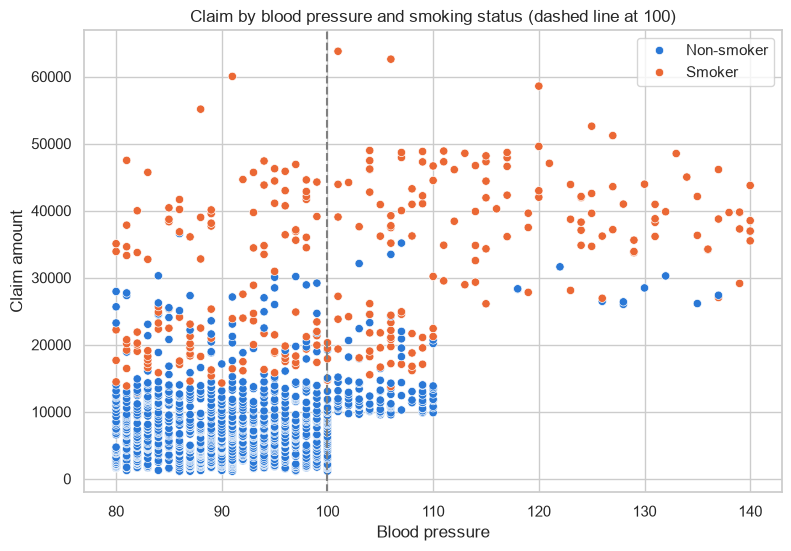

In [6]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="bloodpressure", y="claim", hue="smoking", palette=SMOKING_COLORS)
plt.axvline(100, color="gray", linestyle="--")
plt.title("Claim by blood pressure and smoking status (dashed line at 100)")
plt.xlabel("Blood pressure")
plt.ylabel("Claim amount")
plt.legend(title="")
plt.show()

What this shows:

| Blood pressure | Non-smokers: n | Median claim | Smokers: n | Median claim |
|---|---|---|---|---|
| 80 to 100 | 942 | 6,625 | 132 | 23,323 |
| 101 to 110 | 105 | 11,743 | 64 | 25,520 |
| 111 to 140 | 11 | 28,288 | 78 | 39,667 |

- The pattern looks like a series of steps rather than a straight line. Most non-smokers (89%) have blood pressure of 100 or less, with a visible edge at 100.
- Among non-smokers, claims rise with blood pressure, although the highest band has only 11 people.
- Among smokers, high blood pressure largely overlaps with obesity: 68 of the 78 smokers above 110 also have a BMI of 30 or more. With BMI held fixed, blood pressure adds little for obese smokers (medians of 40,044, 43,254 and 40,073 across the three bands).
- The sharp edge at 100 is another pattern that is unusual for real data.

Open question: does blood pressure add anything once smoking and BMI are both taken into account? The charts cannot answer this; it needs the regression in Step 4.

Query: `sql/03_analysis/05_claim_by_bloodpressure.sql`

## 6. The remaining variables: gender, region, diabetic status and children

Smoking is the strongest pattern so far, and a group with more smokers will show higher claims for that reason alone. So alongside each group's median, the tables below show its share of smokers and its median among non-smokers only. Group sizes are printed first because small groups give unreliable medians.

children
0    568
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64


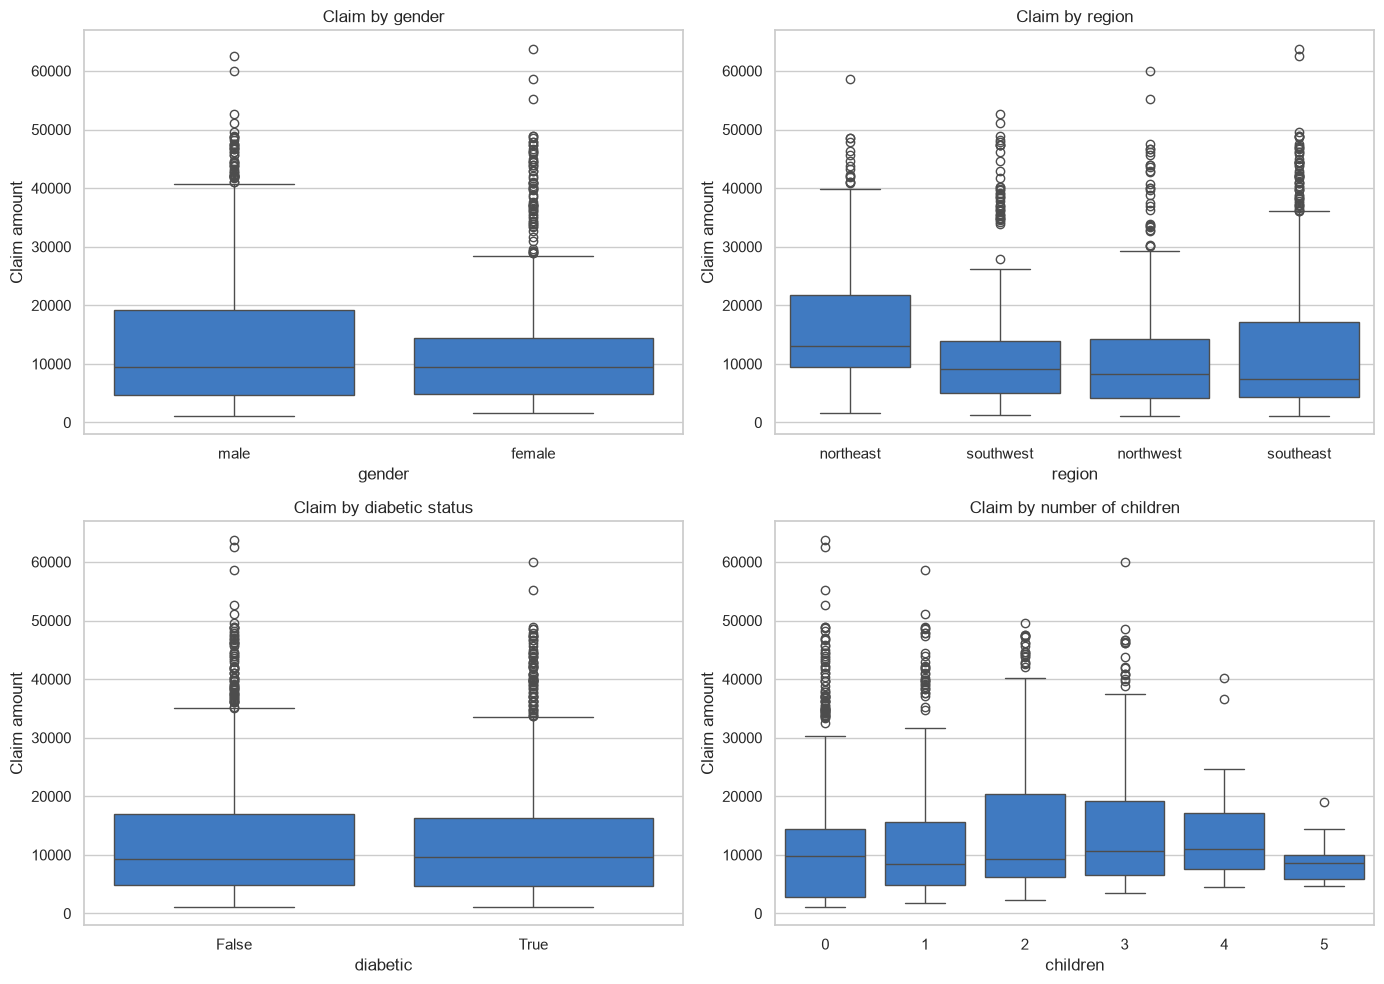

In [7]:
print(df["children"].value_counts().sort_index())

region_order = df.groupby("region")["claim"].median().sort_values(ascending=False).index

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(data=df, x="gender", y="claim", color=BASE_COLOR, ax=axes[0, 0])
axes[0, 0].set_title("Claim by gender")

sns.boxplot(data=df, x="region", y="claim", order=region_order, color=BASE_COLOR, ax=axes[0, 1])
axes[0, 1].set_title("Claim by region")

sns.boxplot(data=df, x="diabetic", y="claim", color=BASE_COLOR, ax=axes[1, 0])
axes[1, 0].set_title("Claim by diabetic status")

sns.boxplot(data=df, x="children", y="claim", color=BASE_COLOR, ax=axes[1, 1])
axes[1, 1].set_title("Claim by number of children")

for ax in axes.flat:
    ax.set_ylabel("Claim amount")

plt.tight_layout()
plt.show()

What this shows:

| Group | n | Median claim | Smokers | Median claim, non-smokers only |
|---|---|---|---|---|
| Male | 670 | 9,439 | 23.7% | 7,147 |
| Female | 662 | 9,413 | 17.4% | 7,639 |
| Northeast | 231 | 13,130 | 29.0% | 11,045 |
| Southwest | 314 | 9,123 | 18.5% | 7,479 |
| Northwest | 345 | 8,311 | 16.8% | 6,710 |
| Southeast | 442 | 7,403 | 20.6% | 6,184 |
| Diabetic | 637 | 9,620 | 21.4% | 7,266 |
| Not diabetic | 695 | 9,302 | 19.9% | 7,421 |

| Children | n | Median claim | Smokers |
|---|---|---|---|
| 0 | 568 | 9,873 | 20.2% |
| 1 | 324 | 8,484 | 18.8% |
| 2 | 240 | 9,265 | 22.9% |
| 3 | 157 | 10,601 | 24.8% |
| 4 | 25 | 11,034 | 12.0% |
| 5 | 18 | 8,590 | 5.6% |

- Gender: median claims are nearly identical. Men's claims vary more, but men also include more smokers (23.7% compared with 17.4%), which likely explains it. Among non-smokers, the medians stay close. Gender may also be tangled with age, which the next section looks at.
- Region: the northeast stands out, with a median of 13,130 compared with 7,403 to 9,123 elsewhere. It has the most smokers (29.0%), but it stays highest among non-smokers too, and it has the lowest share of people with a BMI of 30 or more (46.3%). Smoking and BMI do not fully explain the difference.
- Diabetic status: no visible difference, overall or among non-smokers.
- Children: no consistent trend. Medians move between about 8,500 and 11,000. The groups with 4 and 5 children (25 and 18 people) are too small to trust.
- The unusual high values in all four charts are mostly smokers.

Queries: `sql/03_analysis/03_claim_by_category.sql`, `sql/03_analysis/04_claim_by_children.sql`

## 7. A data quirk: men and women cover different age ranges

While plotting smokers by gender and age, it looked as if men and women covered different age ranges. This chart checks that for everyone.

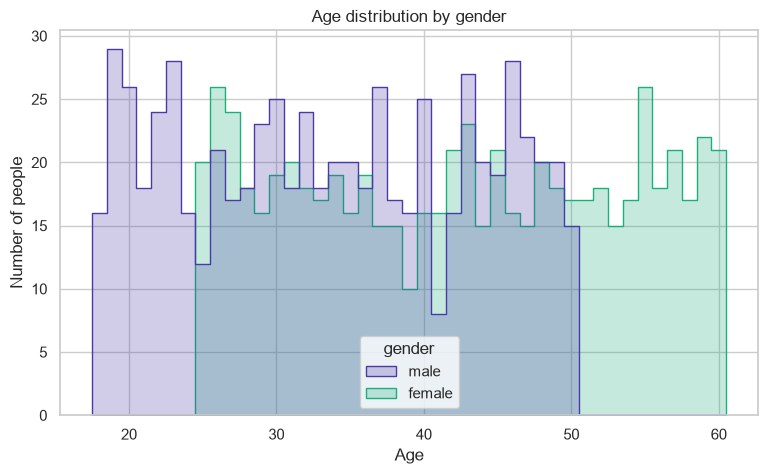

,min,max,count
gender,,,
female,25.0,60.0,662
male,18.0,50.0,670


In [8]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="age", hue="gender", palette=GENDER_COLORS,
             discrete=True, element="step")  # one bar per whole age
plt.title("Age distribution by gender")
plt.xlabel("Age")
plt.ylabel("Number of people")
plt.show()

df.groupby("gender")["age"].agg(["min", "max", "count"])

What this shows:

| | Youngest | Oldest |
|---|---|---|
| Men | 18 | 50 |
| Women | 25 | 60 |

There are no men over 50 and no women under 25, for smokers and non-smokers alike. That is very unlikely in a real customer base. It has two consequences:

- Gender and age are confounded. Any difference in claims between men and women could partly be an age difference, so in Step 4 gender should only be interpreted from a model that also includes age.
- It adds to the signs that the data may be synthetic, alongside the 47.9% diabetes rate (Step 2), the clean BMI cutoff at 30, and the edge in blood pressure at 100.

This finding is recorded in `docs/project_log.md`.

Query: `sql/02_profiling/06_age_range_by_gender.sql`

## 8. Correlation matrix

A step back to look at all pairs of variables at once. Pearson correlation measures how strongly two variables move together in a straight line, from -1 (perfectly opposite) through 0 (no straight-line relationship) to +1 (perfectly together). Yes/no variables are coded as 0 and 1 (smoker, diabetic, and male = 1). Region is left out because its four categories have no natural order.

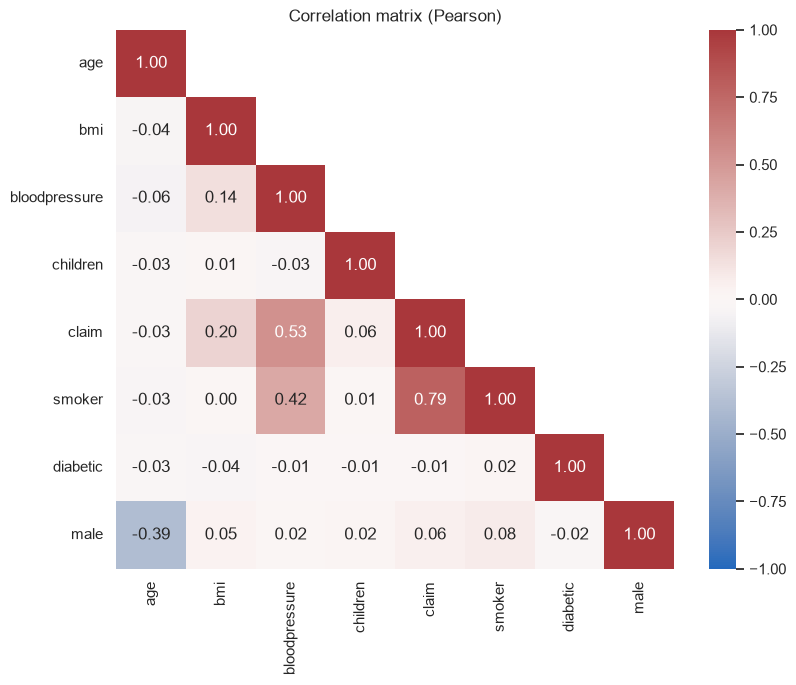

In [9]:
corr_df = df[["age", "bmi", "bloodpressure", "children", "claim"]].copy()
corr_df["smoker"] = df["smoker"].astype(int)
corr_df["diabetic"] = df["diabetic"].astype(int)
corr_df["male"] = (df["gender"] == "male").astype(int)

corr = corr_df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)  # hide the duplicate upper half

plt.figure(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1)
plt.grid(False)
plt.title("Correlation matrix (Pearson)")
plt.show()

What this shows, for each variable's correlation with claim:

- Smoker, 0.79: the strongest, consistent with section 2.
- Blood pressure, 0.53: the second strongest. But blood pressure is also correlated with smoking (0.42), and section 5 showed a step pattern rather than a straight line, so this number overstates a simple straight-line effect.
- BMI, 0.20: this understates BMI's role. Section 4 showed a jump at 30 that happens mainly for smokers. A straight-line measure averages that large jump with almost no change for non-smokers, so it comes out modest.
- Age (-0.03), children (0.06), diabetic (-0.01) and male (0.06): essentially no straight-line relationship. The lack of any age effect is unusual for insurance data.

Between the predictors themselves:

- Male and age, -0.39: the confounding from section 7.
- Smoker and blood pressure, 0.42: the two cannot be read in isolation in a regression.
- All other pairs are weak (between -0.06 and 0.14), so multicollinearity (predictors overlapping so much that a regression cannot separate their effects) should not be a major problem. Step 4 checks this formally with variance inflation factors (VIF).

The main lesson of this chart is its limits: correlation is a useful overview, but it misses both the BMI interaction and the step patterns, which only the charts above revealed.

## 9. What to test in Step 4

These are patterns observed in this notebook. They are hypotheses to be tested formally, not conclusions.

1. Smoking is associated with higher claims and is the strongest single factor.
2. Smoking and obesity interact: the association between a BMI of 30 or more and claims is much larger for smokers than for non-smokers.
3. Blood pressure is associated with higher claims among non-smokers, but among smokers its apparent effect largely overlaps with BMI. Test whether it adds anything once smoking and BMI are both in the model.
4. The northeast is associated with higher claims after controlling for smoking, BMI and age.
5. Age shows little association with claims, which is unusual for insurance data and worth confirming.
6. Gender, diabetic status and number of children show little association with claims once other variables are controlled for.

Modeling notes for Step 4:

- Claims are right-skewed. Compare a model on raw claims with one on log(claim), and check the residuals.
- BMI behaves like a step at 30, not a straight line. Test an indicator for a BMI of 30 or more, interacted with smoking.
- Gender and age are confounded. Interpret gender only from a model that also includes age.
- The groups with 4 and 5 children are small (25 and 18 people). Consider grouping them as "3 or more".
- `Id` is never used as a predictor, because the file is sorted by claim (Step 2).